# Close-based triangular arbitrage study on Binance stablecoin markets

Original exploratory notebook (hourly candles, 2020-01 to 2026-10). It measures the gap between the direct
stablecoin rates and the rates implied through BTC, enumerates triangular cycles, and backtests choosing the
best cycle at every hourly close.

> **Read `docs/errata.md` before using the gap statistics (cells 1 and 3).** The implied rate through BTC is
> inverted in cell 1, which inflates the reported gaps (USDC/USDT mean |gap| 10.8 bps reported vs 1.4 bps corrected).
> The cycle enumeration and the backtest (cells 2, 4 and 5) do not use that quantity and are unaffected.
> The backtest also values every conversion at the candle close, which is *not* executable: see `docs/findings.md`
> for what the live order-book version of the same idea found.

Run from the `notebooks/` directory; data comes from `../data` (see `data/README.md`).


Dataset guardado en: ../data/arbitrage_hourly_dataset.csv


,USDC_USD_low_direct,USDC_USD_low_btc_a,USDC_USD_low_btc_b,USDC_USD_low_btc_implied,USDC_USD_low_gap_bps,USDC_USD_high_direct,USDC_USD_high_btc_a,USDC_USD_high_btc_b,USDC_USD_high_btc_implied,USDC_USD_high_gap_bps,...,USDT_USD_high_abs_gap_bps,USDT_USD_high_cumulative_abs_gap_bps,USDT_USD_close_abs_gap_bps,USDT_USD_close_cumulative_abs_gap_bps,USDC_USDT_low_abs_gap_bps,USDC_USDT_low_cumulative_abs_gap_bps,USDC_USDT_high_abs_gap_bps,USDC_USDT_high_cumulative_abs_gap_bps,USDC_USDT_close_abs_gap_bps,USDC_USDT_close_cumulative_abs_gap_bps
timestamp,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,68.725899,68.725899,80.047045,80.047045,70.905402,70.905402
2020-01-01 01:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,69.062621,137.788520,74.844271,154.891316,77.630116,148.535518
2020-01-01 02:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,67.944713,205.733234,75.827148,230.718464,66.997495,215.533013
2020-01-01 03:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,64.378661,270.111894,76.080450,306.798914,66.009904,281.542917
2020-01-01 04:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,67.535060,337.646954,75.189859,381.988773,75.665413,357.208330


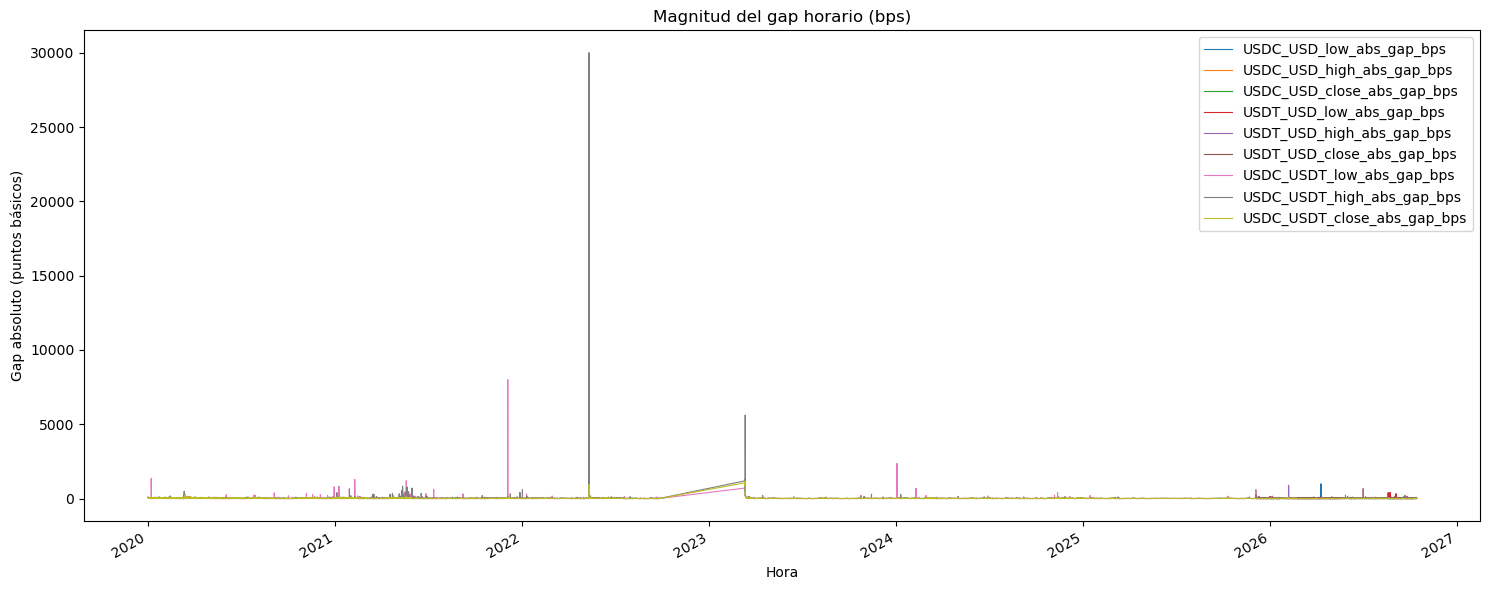

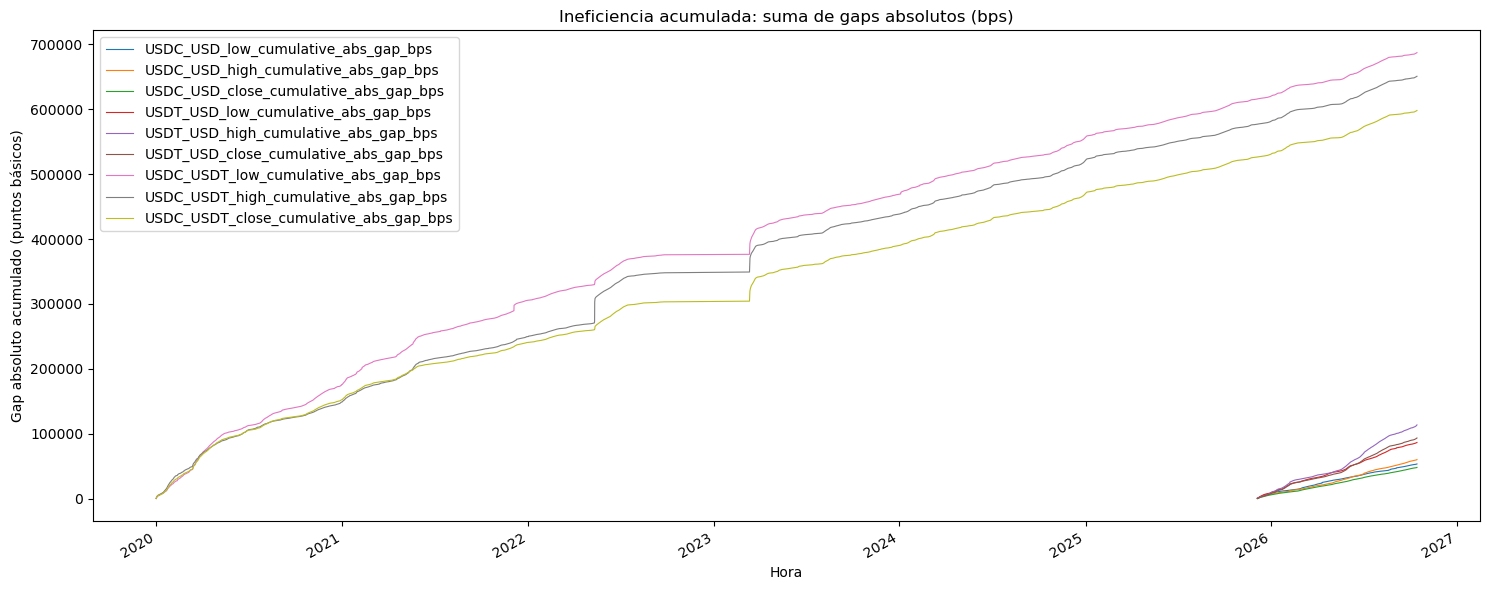

In [7]:
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/binance_hourly_long.csv.gz")

def find_column(candidates):
    return next((c for c in candidates if c in df.columns), None)

time_col = find_column(["timestamp", "datetime", "date", "open_time", "time"])
symbol_col = find_column(["symbol", "pair", "market"])
low_col = find_column(["low", "min"])
high_col = find_column(["high", "max"])
close_col = find_column(["close", "closing", "last"])

required = {
    "time": time_col,
    "symbol": symbol_col,
    "low": low_col,
    "high": high_col,
    "close": close_col,
}
missing = [name for name, col in required.items() if col is None]
if missing:
    raise ValueError(
        f"Faltan columnas requeridas: {missing}. "
        f"Columnas disponibles: {df.columns.tolist()}"
    )

# Pares estables que se comparan directamente y mediante BTC.
stable_pairs = [
    ("USDC", "USD"),
    ("USDT", "USD"),
    ("USDC", "USDT"),
]
assets = sorted({"BTC", "USD", "USDT", "USDC"}, key=len, reverse=True)

def parse_symbol(symbol):
    text = re.sub(r"[^A-Z0-9]", "", str(symbol).upper())
    for quote in assets:
        if text.endswith(quote) and text[:-len(quote)]:
            return text[:-len(quote)], quote
    return None, None

parsed = df[symbol_col].map(parse_symbol)
df["_base"] = parsed.map(lambda item: item[0])
df["_quote"] = parsed.map(lambda item: item[1])

# Convierte timestamps numéricos de segundos o milisegundos, si corresponde.
if pd.api.types.is_numeric_dtype(df[time_col]):
    unit = "ms" if df[time_col].dropna().abs().max() > 1e11 else "s"
    df[time_col] = pd.to_datetime(df[time_col], unit=unit, utc=True)
else:
    df[time_col] = pd.to_datetime(df[time_col], utc=True)

for col in [low_col, high_col, close_col]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=["_base", "_quote", time_col, low_col, high_col, close_col]
)

# Un OHLC por mercado y hora.
market_data = {}
for (base, quote), group in df.groupby(["_base", "_quote"]):
    market_data[(base, quote)] = (
        group.groupby(time_col)[[low_col, high_col, close_col]]
        .last()
        .sort_index()
    )

def directed_ohlc(base, quote):
    """OHLC de la tasa: unidades de quote por una unidad de base."""
    if (base, quote) in market_data:
        return market_data[(base, quote)]

    if (quote, base) in market_data:
        inverse = market_data[(quote, base)]
        return pd.DataFrame(
            {
                low_col: 1 / inverse[high_col],
                high_col: 1 / inverse[low_col],
                close_col: 1 / inverse[close_col],
            },
            index=inverse.index,
        )

    return None

results = {}

for coin_a, coin_b in stable_pairs:
    direct = directed_ohlc(coin_a, coin_b)
    btc_a = directed_ohlc("BTC", coin_a)
    btc_b = directed_ohlc("BTC", coin_b)

    if direct is None or btc_a is None or btc_b is None:
        print(f"Se omite {coin_a}/{coin_b}: falta un mercado directo o BTC.")
        continue

    for field, label in [
        (low_col, "low"),
        (high_col, "high"),
        (close_col, "close"),
    ]:
        aligned = pd.concat(
            [
                direct[field].rename("direct"),
                btc_a[field].rename("btc_a"),
                btc_b[field].rename("btc_b"),
            ],
            axis=1,
        ).dropna()

        if aligned.empty:
            continue

        # Tasa implícita coin_a/coin_b: BTC/coin_b dividido por BTC/coin_a.
        aligned["btc_implied"] = aligned["btc_a"] / aligned["btc_b"]
        aligned["gap_bps"] = (
            (aligned["direct"] - aligned["btc_implied"])
            / aligned["btc_implied"]
            * 10_000
        )

        prefix = f"{coin_a}_{coin_b}_{label}"
        for column in ["direct", "btc_a", "btc_b", "btc_implied", "gap_bps"]:
            results[f"{prefix}_{column}"] = aligned[column]

if not results:
    raise ValueError(
        "No se pudo calcular ningún par. Revisa los símbolos y los datos del CSV."
    )

arbitrage_dataset = pd.DataFrame(results).sort_index()
arbitrage_dataset.index.name = "timestamp"

gap_columns = [
    col for col in arbitrage_dataset.columns
    if col.endswith("_gap_bps")
]

# Magnitud del gap y suma acumulada, sin importar la dirección.
abs_gap_columns = []
cumulative_columns = []

for col in gap_columns:
    abs_col = col.replace("_gap_bps", "_abs_gap_bps")
    cumulative_col = col.replace("_gap_bps", "_cumulative_abs_gap_bps")

    arbitrage_dataset[abs_col] = arbitrage_dataset[col].abs()
    arbitrage_dataset[cumulative_col] = arbitrage_dataset[abs_col].cumsum()

    abs_gap_columns.append(abs_col)
    cumulative_columns.append(cumulative_col)

output_path = Path("../data/arbitrage_hourly_dataset.csv")
arbitrage_dataset.to_csv(output_path)
print(f"Dataset guardado en: {output_path.resolve()}")
display(arbitrage_dataset.head())

arbitrage_dataset[abs_gap_columns].plot(
    figsize=(15, 6),
    linewidth=0.8,
    title="Magnitud del gap horario (bps)",
)
plt.ylabel("Gap absoluto (puntos básicos)")
plt.xlabel("Hora")
plt.tight_layout()
plt.show()

arbitrage_dataset[cumulative_columns].plot(
    figsize=(15, 6),
    linewidth=0.8,
    title="Ineficiencia acumulada: suma de gaps absolutos (bps)",
)
plt.ylabel("Gap absoluto acumulado (puntos básicos)")
plt.xlabel("Hora")
plt.tight_layout()
plt.show()

In [8]:
import itertools

fee_rate = 0.000  # 0.1 % por operación; cámbialo según tu comisión
route_assets = ["USDT", "USDC", "USD", "BTC"]

if not 0 <= fee_rate < 1:
    raise ValueError("fee_rate debe estar entre 0 y 1.")

# Tasas de conversión: unidades de quote por cada unidad de base.
close_rates = {}
for base in route_assets:
    for quote in route_assets:
        if base == quote:
            continue

        if (base, quote) in market_data:
            close_rates[(base, quote)] = market_data[(base, quote)]["close"]
        elif (quote, base) in market_data:
            close_rates[(base, quote)] = 1 / market_data[(quote, base)]["close"]

# Busca todos los ciclos simples cerrados, conservando cada dirección.
cycles = set()
for length in range(2, len(route_assets) + 1):
    for cycle in itertools.permutations(route_assets, length):
        if not all(
            (cycle[i], cycle[(i + 1) % length]) in close_rates
            for i in range(length)
        ):
            continue

        rotations = [
            cycle[i:] + cycle[:i]
            for i in range(length)
        ]
        canonical_cycle = min(
            rotations,
            key=lambda r: tuple(route_assets.index(asset) for asset in r),
        )
        cycles.add(canonical_cycle)

gross_returns = {}
net_profit_bps = {}

for cycle in sorted(cycles):
    route = cycle + (cycle[0],)
    route_label = " → ".join(route)

    edge_rates = pd.concat(
        [
            close_rates[(route[i], route[i + 1])].rename(f"edge_{i}")
            for i in range(len(route) - 1)
        ],
        axis=1,
    ).dropna()

    gross = edge_rates.prod(axis=1)
    net = gross * (1 - fee_rate) ** (len(route) - 1)

    gross_returns[route_label] = gross
    net_profit_bps[route_label] = (net - 1) * 10_000

gross_df = pd.DataFrame(gross_returns)
net_bps_df = pd.DataFrame(net_profit_bps)

# Etiqueta cada resultado con el momento de cierre de la vela.
close_index = net_bps_df.index + pd.Timedelta(hours=1) - pd.Timedelta(milliseconds=1)
gross_df.index = close_index
net_bps_df.index = close_index
gross_df.index.name = "candle_close"
net_bps_df.index.name = "candle_close"

best_route = net_bps_df.idxmax(axis=1)
best_profit_bps = net_bps_df.max(axis=1)

arbitrage_close = pd.DataFrame({
    "best_route": best_route,
    "best_net_profit_bps": best_profit_bps,
    "profitable_after_fees": best_profit_bps > 0,
})

display(arbitrage_close.tail())
display(net_bps_df.tail())

print("Ciclos evaluados:")
for route in net_bps_df.columns:
    print(f"- {route}")

,best_route,best_net_profit_bps,profitable_after_fees
candle_close,,,
2026-10-13 19:59:59.999000+00:00,USDT → USD → BTC → USDC → USDT,2.200123,True
2026-10-13 20:59:59.999000+00:00,USDT → BTC → USD → USDT,1.087564,True
2026-10-13 21:59:59.999000+00:00,USDT → USDC → USD → BTC → USDT,4.888784,True
2026-10-13 22:59:59.999000+00:00,USDC → USD → BTC → USDC,8.084726,True
2026-10-13 23:59:59.999000+00:00,USDT → BTC → USD → USDT,9.668804,True


,USD → BTC → USD,USDC → BTC → USDC,USDC → BTC → USD → USDC,USDC → USD → USDC,USDC → USD → BTC → USDC,USDT → BTC → USDT,USDT → BTC → USD → USDT,USDT → BTC → USD → USDC → USDT,USDT → BTC → USDC → USDT,USDT → BTC → USDC → USD → USDT,USDT → USD → USDT,USDT → USD → BTC → USDT,USDT → USD → BTC → USDC → USDT,USDT → USD → USDC → USDT,USDT → USD → USDC → BTC → USDT,USDT → USDC → USDT,USDT → USDC → BTC → USDT,USDT → USDC → BTC → USD → USDT,USDT → USDC → USD → USDT,USDT → USDC → USD → BTC → USDT
candle_close,,,,,,,,,,,,,,,,,,,,
2026-10-13 19:59:59.999000+00:00,-1.110223e-12,0.000000e+00,-2.110165,0.000000e+00,2.110610,0.0,-1.896853,-1.807376,0.302853,0.213357,0.000000e+00,1.897212,2.200123,0.089494,-0.213352,0.0,-0.302844,-2.199639,-0.089493,1.807702
2026-10-13 20:59:59.999000+00:00,0.000000e+00,-1.110223e-12,0.855921,0.000000e+00,-0.855848,0.0,1.087564,0.979632,0.123700,0.231624,-1.110223e-12,-1.087446,-0.963759,-0.107921,-0.231618,0.0,-0.123699,0.963852,0.107922,-0.979536
2026-10-13 21:59:59.999000+00:00,0.000000e+00,0.000000e+00,-4.654910,-1.110223e-12,4.657078,0.0,-4.679603,-4.886395,-0.231593,-0.024704,0.000000e+00,4.681793,4.450092,-0.206889,0.024704,0.0,0.231598,-4.448113,0.206893,4.888784
2026-10-13 22:59:59.999000+00:00,0.000000e+00,-1.110223e-12,-8.078195,-1.110223e-12,8.084726,0.0,-7.558268,-7.664994,0.413536,0.520347,0.000000e+00,7.563985,7.977834,-0.106806,-0.520320,0.0,-0.413519,-7.971474,0.106807,7.670873
2026-10-13 23:59:59.999000+00:00,0.000000e+00,0.000000e+00,9.382479,-1.110223e-12,-9.373684,0.0,9.668804,9.561935,0.179288,0.286056,-1.110223e-12,-9.659464,-9.480349,-0.106765,-0.286048,0.0,-0.179285,9.489346,0.106766,-9.552801


Ciclos evaluados:
- USD → BTC → USD
- USDC → BTC → USDC
- USDC → BTC → USD → USDC
- USDC → USD → USDC
- USDC → USD → BTC → USDC
- USDT → BTC → USDT
- USDT → BTC → USD → USDT
- USDT → BTC → USD → USDC → USDT
- USDT → BTC → USDC → USDT
- USDT → BTC → USDC → USD → USDT
- USDT → USD → USDT
- USDT → USD → BTC → USDT
- USDT → USD → BTC → USDC → USDT
- USDT → USD → USDC → USDT
- USDT → USD → USDC → BTC → USDT
- USDT → USDC → USDT
- USDT → USDC → BTC → USDT
- USDT → USDC → BTC → USD → USDT
- USDT → USDC → USD → USDT
- USDT → USDC → USD → BTC → USDT


,mean_abs_gap_bps,median_abs_gap_bps,std_gap_bps,max_abs_gap_bps,share_abs_gt_10bps,share_abs_gt_50bps,observations
USDT_USD_close_gap_bps,12.405,10.605,12.979,83.253,0.071,0.000,7528
USDC_USDT_close_gap_bps,10.793,7.383,23.432,1171.424,0.379,0.014,55429
USDC_USD_close_gap_bps,6.376,4.590,9.079,74.782,0.026,0.000,7528


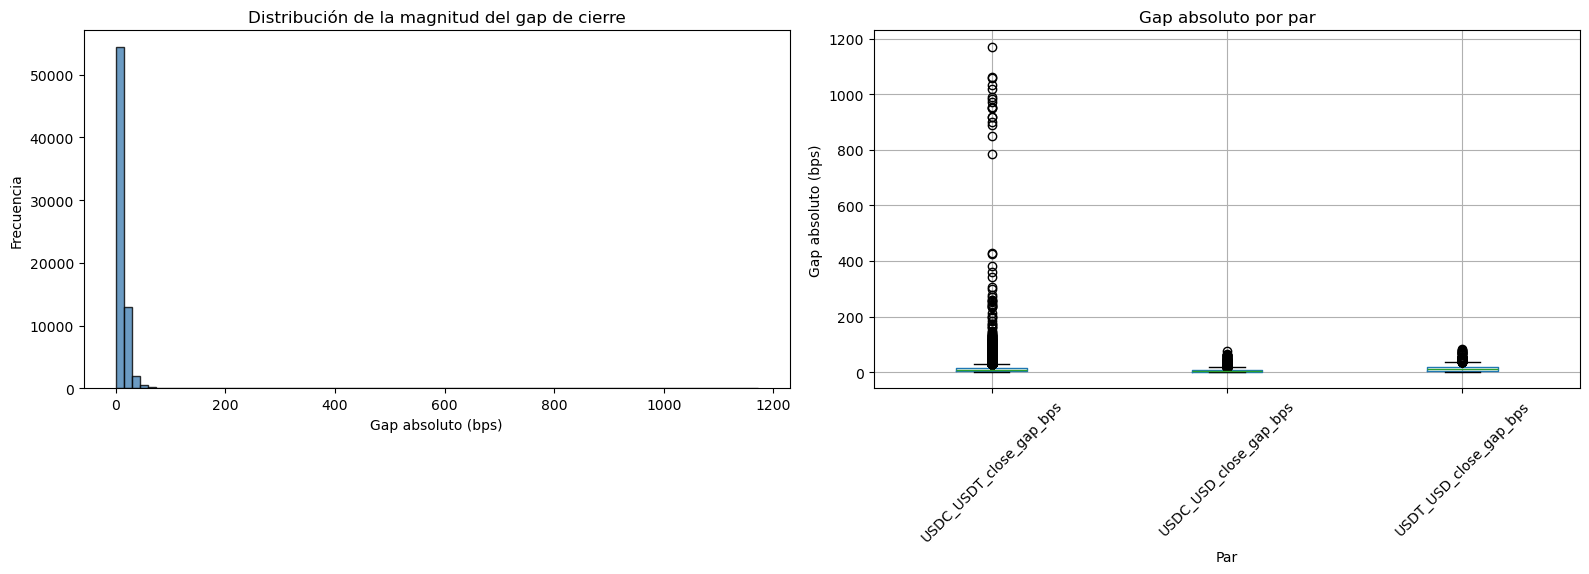

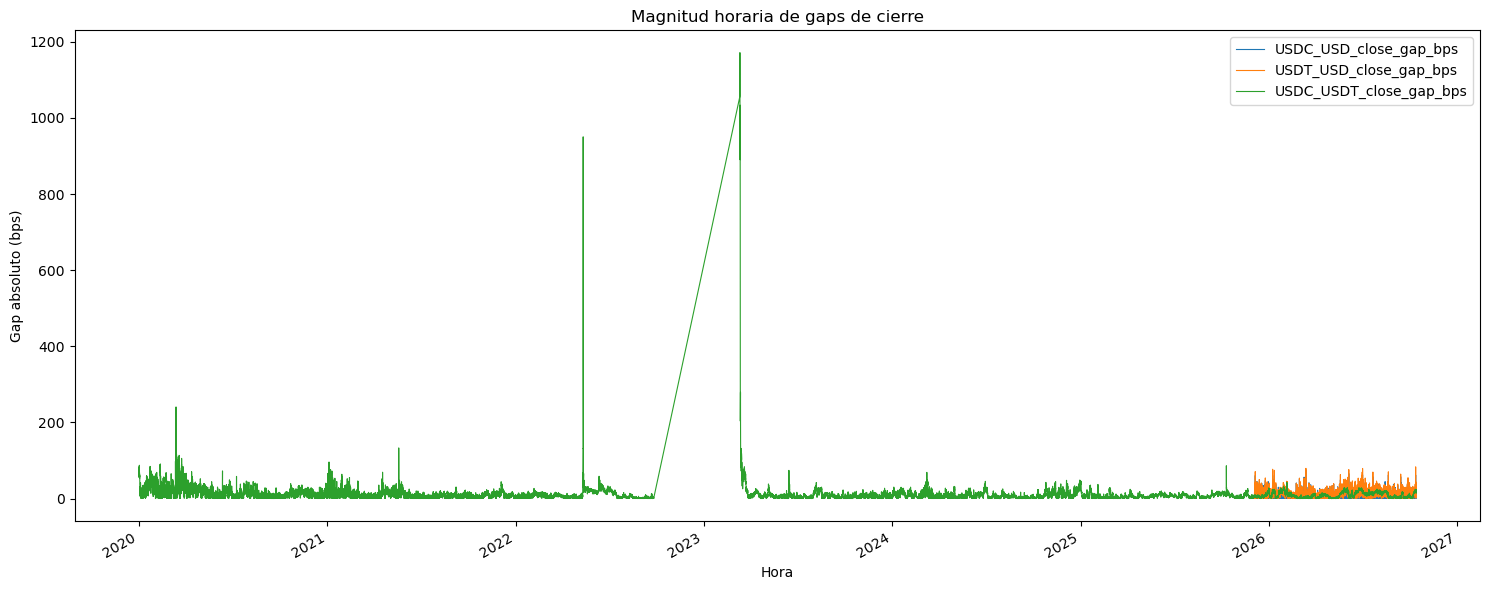

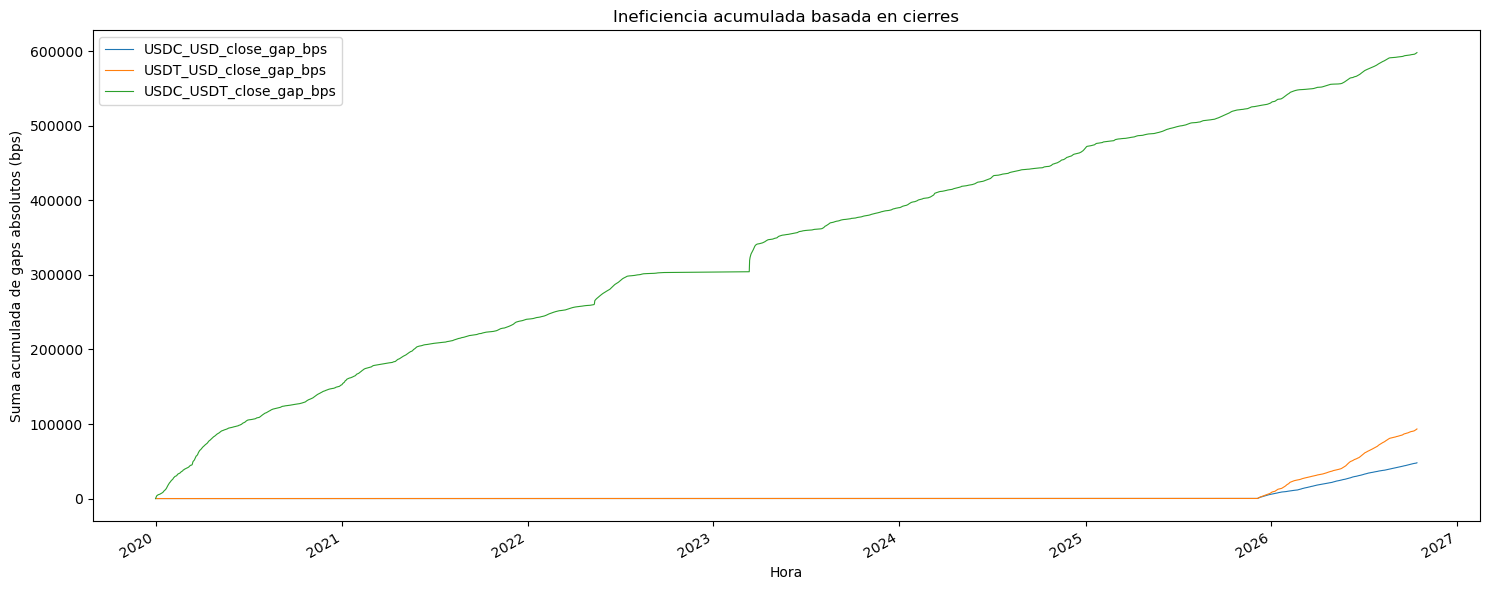

Dataset actualizado: ../data/arbitrage_hourly_dataset.csv


In [10]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Carga el dataset generado por la celda anterior.
dataset_path = Path("../data/arbitrage_hourly_dataset.csv")
arbitrage_dataset = pd.read_csv(
    dataset_path,
    index_col="timestamp",
    parse_dates=True,
)

# Selecciona únicamente los gaps de cierre.
gap_cols = [
    col for col in arbitrage_dataset.columns
    if col.endswith("_close_gap_bps")
]
gap_df = arbitrage_dataset[gap_cols].apply(pd.to_numeric, errors="coerce")

if gap_df.empty:
    raise ValueError(
        "No hay columnas de gaps de cierre. "
        "Comprueba que la celda de cálculo haya generado columnas *_close_gap_bps."
    )

# Magnitud del gap y suma acumulada, sin importar la dirección.
abs_gap_df = gap_df.abs()
cumulative_abs_gap_df = abs_gap_df.fillna(0).cumsum()

for col in gap_cols:
    abs_col = col.replace("_gap_bps", "_abs_gap_bps")
    cumulative_col = col.replace("_gap_bps", "_cumulative_abs_gap_bps")
    arbitrage_dataset[abs_col] = abs_gap_df[col]
    arbitrage_dataset[cumulative_col] = cumulative_abs_gap_df[col]

# Resumen estadístico por par.
stats = pd.DataFrame({
    "mean_abs_gap_bps": abs_gap_df.mean(),
    "median_abs_gap_bps": abs_gap_df.median(),
    "std_gap_bps": gap_df.std(),
    "max_abs_gap_bps": abs_gap_df.max(),
    "share_abs_gt_10bps": (abs_gap_df > 10).mean(),
    "share_abs_gt_50bps": (abs_gap_df > 50).mean(),
    "observations": gap_df.count(),
}).sort_values("mean_abs_gap_bps", ascending=False)

display(stats.round(3))

# Distribución de la magnitud de los gaps de cierre.
flat_abs = abs_gap_df.melt(
    var_name="pair",
    value_name="abs_gap_bps",
).dropna()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].hist(
    flat_abs["abs_gap_bps"],
    bins=80,
    color="steelblue",
    edgecolor="black",
    alpha=0.8,
)
axes[0].set_title("Distribución de la magnitud del gap de cierre")
axes[0].set_xlabel("Gap absoluto (bps)")
axes[0].set_ylabel("Frecuencia")

flat_abs.boxplot(
    column="abs_gap_bps",
    by="pair",
    ax=axes[1],
    rot=45,
    grid=True,
)
axes[1].set_title("Gap absoluto por par")
axes[1].set_xlabel("Par")
axes[1].set_ylabel("Gap absoluto (bps)")

plt.suptitle("")
plt.tight_layout()
plt.show()

# Evolución horaria de la magnitud del gap.
abs_gap_df.plot(
    figsize=(15, 6),
    linewidth=0.8,
    title="Magnitud horaria de gaps de cierre",
)
plt.ylabel("Gap absoluto (bps)")
plt.xlabel("Hora")
plt.tight_layout()
plt.show()

# Ineficiencia acumulada: suma de gaps absolutos de cierre.
cumulative_abs_gap_df.plot(
    figsize=(15, 6),
    linewidth=0.8,
    title="Ineficiencia acumulada basada en cierres",
)
plt.ylabel("Suma acumulada de gaps absolutos (bps)")
plt.xlabel("Hora")
plt.tight_layout()
plt.show()

# Guarda el dataset con las columnas de magnitud y acumulado.
arbitrage_dataset.to_csv(dataset_path)
print(f"Dataset actualizado: {dataset_path.resolve()}")

Período: 2026-04-13 23:00:00+00:00 — 2026-10-13 23:00:00+00:00
Activos: ['BTC', 'USD', 'USDC', 'USDT']
Comisión estándar: 0.100%
Comisión USDC/USDT: 0.000%


,initial_capital,final_capital,total_return_pct,CAGR_pct,max_drawdown_pct,sharpe_hourly_annualized,trades,win_rate_pct,avg_trade_return_bps,profit_factor
source_asset,,,,,,,,,,
BTC,10000,10417.4767,4.1748,8.5056,0.0,6.6014,40,100.0,10.2346,inf
USD,10000,10417.4767,4.1748,8.5056,0.0,6.6014,40,100.0,10.2346,inf
USDC,10000,10416.8629,4.1686,8.4929,0.0,6.5958,40,100.0,10.2198,inf
USDT,10000,10415.8330,4.1583,8.4715,0.0,6.5855,40,100.0,10.1951,inf


,source_asset,timestamp,route,gross_return,net_return_bps
140,USDT,2026-07-08 08:59:59.999000+00:00,USDT → USDC → BTC → USD → USDT,1.000574,5.744510
141,USDT,2026-07-22 02:59:59.999000+00:00,USDT → USD → BTC → USDC → USDT,1.002552,25.519194
142,USDT,2026-08-02 08:59:59.999000+00:00,USDT → BTC → USD → USDC → USDT,1.000828,8.283692
143,USDT,2026-08-14 19:59:59.999000+00:00,USDT → USDC → BTC → USD → USDT,1.001439,14.385767
144,USDT,2026-08-19 18:59:59.999000+00:00,USDT → USD → BTC → USDC → USDT,1.000412,4.117729
145,USDT,2026-08-21 03:59:59.999000+00:00,USDT → USD → BTC → USDC → USDT,1.002389,23.889416
146,USDT,2026-08-31 02:59:59.999000+00:00,USDT → USDC → BTC → USD → USDT,1.001220,12.196010
147,USDT,2026-09-01 21:59:59.999000+00:00,USDT → USDC → USD → BTC → USDT,1.000141,1.407207
148,USDT,2026-09-10 14:59:59.999000+00:00,USDT → BTC → USD → USDC → USDT,1.000021,0.205928
149,USDT,2026-09-14 00:59:59.999000+00:00,USDT → USDC → USD → BTC → USDT,1.002344,23.435050


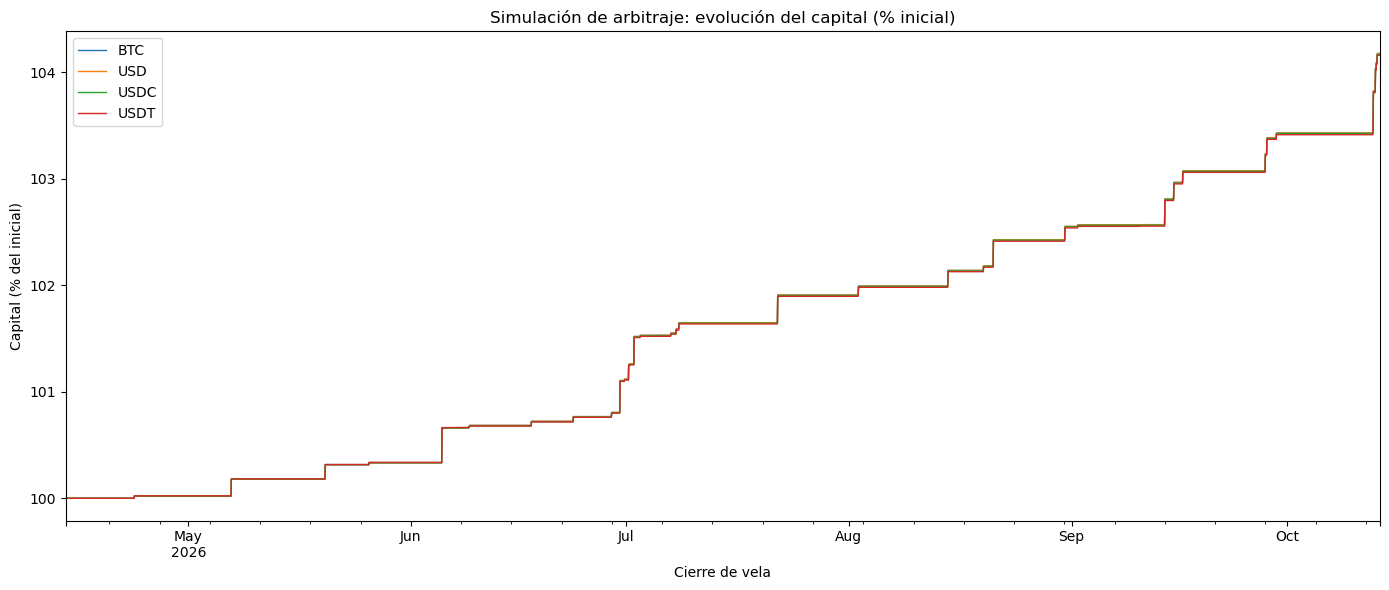

In [11]:
# Configuración
default_fee_rate = 0.001  # 0,100 % por operación
pair_fee_overrides = {
    frozenset(("USDC", "USDT")): 0.0,  # Sin comisión en ambas direcciones
}
initial_capital = 10_000
min_profit_bps = 0.01  # Tolerancia para evitar operaciones por ruido numérico
lookback_months = 6

if not 0 <= default_fee_rate < 1:
    raise ValueError("default_fee_rate debe estar entre 0 y 1.")
if initial_capital <= 0:
    raise ValueError("initial_capital debe ser mayor que cero.")

# Construye tasas dirigidas a partir de los mercados disponibles.
# La tasa representa unidades de quote recibidas por unidad de base.
simulation_rates = {}
for (base, quote), market in market_data.items():
    close = pd.to_numeric(market["close"], errors="coerce")
    close = close.where(close > 0).dropna()

    simulation_rates[(base, quote)] = close
    simulation_rates[(quote, base)] = 1 / close

assets = sorted(
    {asset for edge in simulation_rates for asset in edge},
)
graph = {asset: set() for asset in assets}
for base, quote in simulation_rates:
    graph[base].add(quote)

if not assets:
    raise ValueError("No hay mercados disponibles para simular.")

# Limita los datos a los últimos seis meses respecto al último dato disponible.
latest_time = max(series.index.max() for series in simulation_rates.values())
start_time = latest_time - pd.DateOffset(months=lookback_months)

simulation_rates = {
    edge: series.loc[(series.index >= start_time) & (series.index <= latest_time)]
    for edge, series in simulation_rates.items()
}
simulation_rates = {
    edge: series for edge, series in simulation_rates.items() if not series.empty
}

# Enumera todos los ciclos simples: 1, 2, ... hasta N-1 activos intermedios.
# Cada ciclo empieza y termina en el mismo activo; ambas direcciones se evalúan.
routes_by_source = {asset: [] for asset in assets}

for source in assets:
    def explore(path):
        current = path[-1]

        if len(path) >= 2 and source in graph.get(current, set()):
            routes_by_source[source].append(tuple(path))

        for next_asset in graph.get(current, set()):
            if next_asset != source and next_asset not in path:
                explore(path + [next_asset])

    explore([source])

# Calcula el rendimiento neto de cada ciclo en cada cierre disponible.
route_returns = {}
for source, routes in routes_by_source.items():
    for route in routes:
        edges = list(zip(route, route[1:] + (source,)))
        edge_series = []

        for base, quote in edges:
            series = simulation_rates.get((base, quote))
            if series is None:
                break
            edge_series.append(series.rename(f"{base}->{quote}"))

        if len(edge_series) != len(edges):
            continue

        aligned = pd.concat(edge_series, axis=1).dropna()
        if aligned.empty:
            continue

        gross = aligned.prod(axis=1)
        total_fees = sum(
            pair_fee_overrides.get(
                frozenset((base, quote)),
                default_fee_rate,
            )
            for base, quote in edges
        )

        # Comisión aplicada en cada conversión del ciclo.
        fee_factor = 1.0
        for base, quote in edges:
            fee = pair_fee_overrides.get(
                frozenset((base, quote)),
                default_fee_rate,
            )
            fee_factor *= 1 - fee

        route_label = " → ".join(route + (source,))
        route_returns[(source, route_label)] = gross * fee_factor

if not route_returns:
    raise ValueError(
        "No se encontraron ciclos completos en el período seleccionado."
    )

# Simula una cuenta separada por activo de origen.
metric_rows = []
trade_records = []
equity_curves = {}

for source in assets:
    source_routes = {
        label: values
        for (route_source, label), values in route_returns.items()
        if route_source == source
    }
    if not source_routes:
        continue

    returns_df = pd.DataFrame(source_routes).sort_index()
    equity_index = returns_df.index.unique().sort_values()
    equity_factors = pd.Series(1.0, index=equity_index)
    selected_returns = pd.Series(float("nan"), index=equity_index)
    selected_routes = pd.Series(index=equity_index, dtype="object")

    for timestamp, row in returns_df.iterrows():
        available = row.dropna()
        if available.empty:
            continue

        best_route = available.idxmax()
        best_factor = float(available[best_route])
        profit_bps = (best_factor - 1) * 10_000

        if profit_bps > min_profit_bps:
            equity_factors.loc[timestamp] = best_factor
            selected_returns.loc[timestamp] = best_factor - 1
            selected_routes.loc[timestamp] = best_route

            trade_records.append({
                "source_asset": source,
                "timestamp": timestamp + pd.Timedelta(hours=1)
                - pd.Timedelta(milliseconds=1),
                "route": best_route,
                "gross_return": float(
                    returns_df.loc[timestamp, best_route]
                    / _fee_factor
                ) if False else float(best_factor),
                "net_return_bps": profit_bps,
            })

    equity = initial_capital * equity_factors.cumprod()
    equity_curves[source] = equity

    trade_returns = selected_returns.dropna()
    total_return = equity.iloc[-1] / initial_capital - 1
    elapsed_days = max(
        (equity.index[-1] - equity.index[0]).total_seconds() / 86_400,
        1 / 24,
    )
    cagr = (equity.iloc[-1] / initial_capital) ** (365.25 / elapsed_days) - 1

    drawdown = equity / equity.cummax() - 1
    hourly_returns = equity.pct_change().dropna()
    sharpe = (
        hourly_returns.mean() / hourly_returns.std() * (365.25 * 24) ** 0.5
        if len(hourly_returns) > 1 and hourly_returns.std() > 0
        else float("nan")
    )

    gains = trade_returns[trade_returns > 0].sum()
    losses = trade_returns[trade_returns < 0].sum()
    profit_factor = gains / abs(losses) if losses < 0 else float("inf")

    metric_rows.append({
        "source_asset": source,
        "initial_capital": initial_capital,
        "final_capital": equity.iloc[-1],
        "total_return_pct": total_return * 100,
        "CAGR_pct": cagr * 100,
        "max_drawdown_pct": drawdown.min() * 100,
        "sharpe_hourly_annualized": sharpe,
        "trades": int(trade_returns.count()),
        "win_rate_pct": (
            (trade_returns > 0).mean() * 100
            if not trade_returns.empty else 0.0
        ),
        "avg_trade_return_bps": (
            trade_returns.mean() * 10_000
            if not trade_returns.empty else 0.0
        ),
        "profit_factor": profit_factor,
    })

# Etiqueta las operaciones con el rendimiento neto ya deducidas las comisiones.
trades_df = pd.DataFrame(trade_records)
if not trades_df.empty:
    trades_df["gross_return"] = (
        1 + trades_df["net_return_bps"] / 10_000
    )

metrics_df = pd.DataFrame(metric_rows).set_index("source_asset")
print(f"Período: {start_time} — {latest_time}")
print(f"Activos: {assets}")
print(f"Comisión estándar: {default_fee_rate:.3%}")
print(f"Comisión USDC/USDT: {pair_fee_overrides[frozenset(('USDC', 'USDT'))]:.3%}")
display(metrics_df.round(4))
display(trades_df.tail(20))

# Evolución del capital de cada cuenta, normalizada al capital inicial.
equity_pct = pd.DataFrame({
    asset: curve / initial_capital * 100
    for asset, curve in equity_curves.items()
})
equity_pct.plot(
    figsize=(14, 6),
    title="Simulación de arbitraje: evolución del capital (% inicial)",
    linewidth=1,
)
plt.ylabel("Capital (% del inicial)")
plt.xlabel("Cierre de vela")
plt.tight_layout()
plt.show()

In [12]:
import numpy as np
import pandas as pd

annual_hours = 365.25 * 24
summary = []

for asset, equity in equity_curves.items():
    # Completa horas sin operaciones manteniendo el último valor del capital.
    hourly_equity = equity.sort_index().resample("h").last().ffill()
    hourly_returns = hourly_equity.pct_change().dropna()

    if hourly_equity.empty or hourly_returns.empty:
        continue

    total_return = hourly_equity.iloc[-1] / initial_capital - 1
    elapsed_years = (
        (hourly_equity.index[-1] - hourly_equity.index[0]).total_seconds()
        / (365.25 * 24 * 60 * 60)
    )
    cagr = (
        (hourly_equity.iloc[-1] / initial_capital) ** (1 / elapsed_years) - 1
        if elapsed_years > 0 else np.nan
    )

    volatility = hourly_returns.std() * np.sqrt(annual_hours)
    sharpe = (
        hourly_returns.mean() / hourly_returns.std() * np.sqrt(annual_hours)
        if hourly_returns.std() > 0 else np.nan
    )

    downside_deviation = np.sqrt(
        np.square(hourly_returns.clip(upper=0)).mean()
    ) * np.sqrt(annual_hours)
    sortino = (
        hourly_returns.mean() * annual_hours**0.5 / downside_deviation
        if downside_deviation > 0 else np.nan
    )

    drawdown = hourly_equity / hourly_equity.cummax() - 1
    max_drawdown = drawdown.min()
    calmar = cagr / abs(max_drawdown) if max_drawdown < 0 else np.nan

    var_95 = hourly_returns.quantile(0.05)
    cvar_95 = hourly_returns[hourly_returns <= var_95].mean()

    asset_trades = (
        trades_df[trades_df["source_asset"] == asset]
        if not trades_df.empty else pd.DataFrame()
    )

    summary.append({
        "source_asset": asset,
        "initial_capital": initial_capital,
        "final_capital": hourly_equity.iloc[-1],
        "total_return_pct": total_return * 100,
        "CAGR_pct": cagr * 100,
        "annual_volatility_pct": volatility * 100,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "max_drawdown_pct": max_drawdown * 100,
        "Calmar": calmar,
        "hourly_VaR_95_pct": var_95 * 100,
        "hourly_CVaR_95_pct": cvar_95 * 100,
        "trades": len(asset_trades),
    })

portfolio_summary = (
    pd.DataFrame(summary)
    .set_index("source_asset")
    .sort_values("CAGR_pct", ascending=False)
)

display(portfolio_summary.round(3))

,initial_capital,final_capital,total_return_pct,CAGR_pct,annual_volatility_pct,Sharpe,Sortino,max_drawdown_pct,Calmar,hourly_VaR_95_pct,hourly_CVaR_95_pct,trades
source_asset,,,,,,,,,,,,
USD,10000,10417.477,4.175,8.506,1.238,6.601,NaN,0.0,NaN,0.0,0.0,40
BTC,10000,10417.477,4.175,8.506,1.238,6.601,NaN,0.0,NaN,0.0,0.0,40
USDC,10000,10416.863,4.169,8.493,1.237,6.596,NaN,0.0,NaN,0.0,0.0,40
USDT,10000,10415.833,4.158,8.471,1.236,6.586,NaN,0.0,NaN,0.0,0.0,40
